# Bước 6C — Train full B1/B2 trên 1.600 người

**Đồ án CV nâng cao · Claude tiếp nối pilot của Codex · 06/11/2026**

Pilot của Codex (128 người, 432 bước) đã kiểm code train, thuật toán che và checkpoint. Notebook này train thật trên toàn bộ **1.600 người train**, theo đúng cấu hình bạn train song song trong nhóm đã dùng, để hai lượt đối chiếu được với nhau.

- **B1**: fine-tune toàn bộ InceptionResnetV1 trên ảnh nền DigiFace.
- **B2**: giống B1, thêm che nhân tạo cho 50% lượt ảnh (cùng thuật toán và seed che với pilot).
- Đánh giá trên **200 người validation** chưa xuất hiện lúc train, cùng evaluator bước 5: ảnh nền và 7.700 query che cố định.

Model được lưu sau mỗi epoch. Chạy lại notebook sẽ **nạp model đã lưu thay vì train lại** (mục 1). Test, ROF và MFR2 không được dùng ở đây.

## 1. Cấu hình và chế độ chạy

| | Pilot (Codex) | Full (notebook này) |
|---|---|---|
| Người train | 128 | 1.600 |
| Ảnh train / epoch | 4.608 | 57.600 |
| Lớp được train | block cuối + projection | toàn bộ mạng, BatchNorm cập nhật |
| Epoch / batch | 1 warm-up + 2 / 32 | 5 / 8 |
| LR encoder / classifier | 3e-5 / 1e-3 | 1e-5 / 1e-3 |
| Mixed precision | không | FP16 (AMP) |
| Bước optimizer mỗi nhánh | 432 | 36.000 |

Cột "Full" lấy từ bảng cấu hình của lượt train song song (AdamW, weight decay 1e-4, cross-entropy, seed 20261028). Chọn checkpoint: epoch có DIR validation nền cao nhất tại FPIR ≤ 5%; hòa thì xét DIR query che, rồi epoch sớm hơn.

**Lưu và nạp model.** `CV_TRAIN_MODE` quyết định cách chạy:

- `auto` (mặc định): nếu đã có model lưu với đúng cấu hình và dữ liệu thì nạp lại, không train. Nếu lượt trước dừng giữa chừng thì train tiếp từ epoch cuối đã lưu.
- `retrain`: bỏ qua model đã lưu, train lại từ đầu.

"Đúng cấu hình" được kiểm bằng dấu vân tay gồm cấu hình, danh sách ảnh train, thuật toán che, khởi tạo và mã các ô train (đánh dấu `# [train-code]`). Sửa Markdown không làm mất model đã lưu; sửa code train thì có.

In [1]:
# [train-code]
from __future__ import annotations
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os, sys, json, hashlib, time, math, gc, platform, importlib.metadata
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch
from torch import nn
import torch.nn.functional as F
from facenet_pytorch import InceptionResnetV1
from facenet_pytorch.models.mtcnn import fixed_image_standardization


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/huan_luyen/Train_full_B1_B2.ipynb').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/huan_luyen'
SMOKE = os.environ.get('CV_FULL_SMOKE') == '1'          # chạy thử nhỏ để kiểm code, không phải kết quả
TRAIN_MODE = os.environ.get('CV_TRAIN_MODE', 'auto')     # 'auto' hoặc 'retrain'
assert TRAIN_MODE in {'auto', 'retrain'}
OUT = HERE / ('full_outputs_smoke' if SMOKE else 'full_outputs')
CKPT = HERE / ('checkpoints_full_smoke' if SMOKE else 'checkpoints_full')
TAB, FIG, CACHE = OUT / 'tables', OUT / 'figures', OUT / 'cache'
for p in [OUT, TAB, FIG, CACHE, CKPT]:
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HERE))
START = time.perf_counter()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
DEVICE = 'cuda:0'
assert torch.cuda.is_available(), 'Train full cần GPU NVIDIA'

CFG = {'version': 'full_1600ids_v1', 'seed': 20261028, 'epochs': 2 if SMOKE else 5, 'batch_size': 8,
       'strategy': 'full_fine_tune_all_layers_batchnorm_train_mode',
       'optimizer': 'AdamW', 'lr_encoder': 1e-5, 'lr_head': 1e-3, 'weight_decay': 1e-4,
       'loss': 'cross_entropy', 'amp': 'fp16_autocast_gradscaler', 'gradient_clip': None,
       'occlusion_probability_B2': 0.5,
       'checkpoint_selection': 'max_base_val_DIR_at_FPIR05; tie: occluded_DIR; tie: earlier_epoch',
       'evaluation_batch_size': 256, 'bootstrap_repetitions': 2000,
       'smoke_identities': 24 if SMOKE else None}
SEED = CFG['seed']


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            h.update(b)
    return h.hexdigest()


def digest(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def state_sha(state):
    h = hashlib.sha256()
    for k, t in sorted(state.items()):
        h.update(k.encode()); h.update(t.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.17g')
    return d


def jwrite(x, name):
    (OUT / name).write_text(json.dumps(x, ensure_ascii=False, indent=2, default=str), encoding='utf-8')


def vn(x, d=0):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(x, signed=False):
    s = vn(100 * abs(x), 2)
    return (('+' if x >= 0 else '−') + s if signed else s) + ('' if signed else '%')


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
COLORS = {'B0': '#8a8984', 'B1': '#2a78d6', 'B2': '#eb6834'}

NB_PATH = HERE / 'Train_full_B1_B2.ipynb'
NB_CELLS = json.loads(NB_PATH.read_text(encoding='utf-8'))['cells']
TRAIN_CODE_SHA = digest([''.join(c['source']) for c in NB_CELLS
                         if c['cell_type'] == 'code' and ''.join(c['source']).lstrip().startswith(('# [train-code]', 'def make_spec'))])
ENV = {'python': platform.python_version(), 'torch': torch.__version__,
       'facenet_pytorch': importlib.metadata.version('facenet-pytorch'), 'numpy': np.__version__,
       'gpu': torch.cuda.get_device_name(0),
       'vram_total_MiB': round(torch.cuda.get_device_properties(0).total_memory / 2**20)}
display(pd.DataFrame([{'mục': k, 'giá trị': str(v)} for k, v in
                      {**CFG, 'TRAIN_MODE': TRAIN_MODE, 'SMOKE': SMOKE, **ENV}.items()]))

,mục,giá trị
0,version,full_1600ids_v1
1,seed,20261028
2,epochs,5
3,batch_size,8
4,strategy,full_fine_tune_all_layers_batchnorm_train_mode
5,optimizer,AdamW
6,lr_encoder,1e-05
7,lr_head,0.001
8,weight_decay,0.0001
9,loss,cross_entropy


Thuật toán che dưới đây chép nguyên văn từ notebook augmentation. Ô kế tiếp kiểm SHA của nó với hợp đồng augmentation, nên B2 ở đây che đúng như pilot.

In [2]:
def make_spec(image_id, epoch, partition, force=False):
    seed=int(hashlib.sha256(f"{AUG['seed']}|{partition}|{epoch}|{image_id}".encode()).hexdigest()[:16],16)
    rng=np.random.default_rng(seed)
    applied=bool(force or rng.random()<AUG['train_probability'])
    kind=AUG['kinds'][int(rng.integers(len(AUG['kinds'])))] if applied else 'none'
    box=[0,0,0,0];fill=0
    if applied:
        box=np.array(AUG['boxes'][kind],dtype=int)+rng.integers(-4,5,size=4)
        box=np.clip(box,0,160).tolist()
        fill=int(rng.choice(AUG['fill_values']))
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    return {'image_id':image_id,'epoch':int(epoch),'partition':partition,'seed':str(seed),
            'applied':applied,'kind':kind,'x1':box[0],'y1':box[1],'x2':box[2],'y2':box[3],
            'fill_gray':fill,'mask_pixels':area,'frame_pixels':160*160,
            'mask_fraction_frame':area/(160*160),
            'variant_id':'VAR_'+hashlib.sha256(f'{image_id}|{seed}|{kind}|{box}|{fill}'.encode()).hexdigest()[:24]}

def apply_spec(pixels,spec):
    if pixels.dtype!=np.uint8 or pixels.shape!=(160,160,3):raise ValueError('Expected uint8 RGB160')
    mask=np.zeros((160,160),dtype=np.uint8)
    if bool(spec['applied']):mask[int(spec['y1']):int(spec['y2']),int(spec['x1']):int(spec['x2'])]=1
    if int(mask.sum())!=int(spec['mask_pixels']):raise ValueError('Mask area does not match metadata')
    result=pixels.copy();result[mask.astype(bool)]=int(spec['fill_gray'])
    return result,mask

## 2. Danh sách ảnh và lịch che của B2

Train: mọi ảnh vai trò `train` của 1.600 người (36 ảnh/người); monitor: 4 ảnh/người còn lại, chỉ để xem model học người train tới đâu. Validation giữ nguyên 8.000 ảnh của bước 5.

Lịch che B2 được sinh trước cho từng ảnh ở từng epoch bằng `make_spec`; B1 dùng cùng thứ tự ảnh, không che. Query che của validation dùng lại đúng bảng spec của pilot.

In [3]:
# [train-code]
ADIR = ROOT / 'ban_giao_nhom/augmentation/notebook_outputs'
contract = json.loads((ADIR / 'augmentation_pilot_contract.json').read_text(encoding='utf-8'))
AUG = contract['augmentation']
COMMON_SRC = next(''.join(c['source']) for c in NB_CELLS
                  if c['cell_type'] == 'code' and ''.join(c['source']).startswith('def make_spec'))
assert hashlib.sha256(COMMON_SRC.encode()).hexdigest() == contract['implementation_sha256'], 'Thuật toán che khác notebook augmentation'
ROLE = ROOT / 'ban_giao_nhom/protocol/notebook_outputs/tables/05_image_roles_draft.csv'
DECISIONS = ROOT / 'ban_giao_nhom/quyet_dinh_nhom/input/project_decisions.csv'
assert sha(ROLE) == contract['input_sha256']['roles'] and sha(DECISIONS) == contract['input_sha256']['decisions']
R = pd.read_csv(ROLE, dtype=str, keep_default_na=False)

train_ids = sorted(R[R.partition.eq('train')].canonical_identity.unique())
if SMOKE:
    train_ids = train_ids[:CFG['smoke_identities']]
T = R[R.canonical_identity.isin(train_ids) & R.role.eq('train')].sort_values('image_id').reset_index(drop=True)
M = R[R.canonical_identity.isin(train_ids) & R.role.eq('train_monitor')].sort_values('image_id').reset_index(drop=True)
V = pd.read_csv(ADIR / 'tables/01_validation_roles.csv', dtype=str, keep_default_na=False)
VS = pd.read_csv(ADIR / 'tables/02_validation_query_variant_specs.csv', dtype={'seed': str})
assert sha(ADIR / 'tables/02_validation_query_variant_specs.csv') == contract['validation_spec_sha256']
assert len(V) == 8000 and len(T) == 36 * len(train_ids) and len(M) == 4 * len(train_ids)
assert not set(T.canonical_identity) & set(V.canonical_identity)
for col in ['image_id', 'sha256', 'pixel_sha256', 'photo_group', 'leakage_group', 'guard_group']:
    assert not set(T[col]) & set(M[col]), 'Train/monitor trùng ' + col
    assert not set(pd.concat([T, M])[col]) & set(V[col]), 'Train/validation trùng ' + col
assert not T.partition.isin(['test']).any() and T.source.eq('DigiFace').all()
labels = {x: i for i, x in enumerate(train_ids)}

TS = pd.DataFrame([make_spec(r.image_id, epoch, 'train') for epoch in range(CFG['epochs']) for r in T.itertuples()])
assert TS.groupby('epoch').size().eq(len(T)).all() and TS.variant_id.is_unique
assert TS[TS.applied].mask_fraction_frame.between(.15, .4).all() and TS[~TS.applied].mask_pixels.eq(0).all()
TS.to_csv(TAB / '02_B2_train_variant_specs_full.csv.gz', index=False, float_format='%.17g')
TRAIN_MANIFEST_SHA = digest(T[['image_id', 'sha256', 'canonical_identity']].to_csv(index=False))
SPEC_SHA = digest(TS[['image_id', 'epoch', 'variant_id']].to_csv(index=False))
spec_lookup = {(int(r['epoch']), r['image_id']): r for r in
               TS[['epoch', 'image_id', 'applied', 'x1', 'y1', 'x2', 'y2', 'fill_gray', 'mask_pixels']].to_dict('records')}

cohort = save(pd.DataFrame([
    {'tập': 'train', 'ảnh': len(T), 'người': T.canonical_identity.nunique()},
    {'tập': 'monitor (cùng người train)', 'ảnh': len(M), 'người': M.canonical_identity.nunique()},
    {'tập': 'validation gallery', 'ảnh': int(V.role.eq('gallery').sum()), 'người': V[V.role.eq('gallery')].canonical_identity.nunique()},
    {'tập': 'validation known query', 'ảnh': int(V.role.eq('known_query').sum()), 'người': V[V.role.eq('known_query')].canonical_identity.nunique()},
    {'tập': 'validation unknown query', 'ảnh': int(V.role.eq('unknown_query').sum()), 'người': V[V.role.eq('unknown_query')].canonical_identity.nunique()}]),
    '01_cohort')
display(cohort)
display(pd.crosstab(TS.epoch, TS.kind).rename_axis(index='epoch', columns='kiểu che B2'))

,tập,ảnh,người
0,train,57600,1600
1,monitor (cùng người train),6400,1600
2,validation gallery,300,100
3,validation known query,3700,100
4,validation unknown query,4000,100


kiểu che B2,eyes,left,lower,none,right
epoch,,,,,
0,7182,7145,7149,28749,7375
1,7115,7202,7195,28839,7249
2,7157,7210,7256,28743,7234
3,7188,7259,7173,28768,7212
4,7131,7163,7229,28900,7177


## 3. Nạp ảnh

Mọi ảnh dùng trong notebook (train, monitor, validation) được băm SHA-256 và so với bảng protocol trước khi dùng. Ảnh đọc giống bước 5: xoay theo EXIF, nền trắng nếu có alpha, resize bilinear 160×160, lưu cache uint8 chưa chuẩn hóa. Cache chỉ được dùng lại khi dấu vân tay khớp. Ảnh train được nạp hết vào RAM (khoảng 4,4 GB) để đọc batch ngẫu nhiên nhanh.

In [4]:
# [train-code]
data = pd.concat([T.assign(cohort='train'), M.assign(cohort='monitor'), V.assign(cohort='val')], ignore_index=True)
assert data.image_id.is_unique


def rgb160(r):
    path = ROOT / r.path
    assert sha(path) == r.sha256, 'Ảnh gốc đã đổi: ' + r.path
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(source)
        if 'A' in im.getbands():
            rgba = im.convert('RGBA')
            if (np.asarray(rgba.getchannel('A')) < 255).any():
                im = Image.alpha_composite(Image.new('RGBA', rgba.size, (255, 255, 255, 255)), rgba)
        return np.asarray(im.convert('RGB').resize((160, 160), Image.Resampling.BILINEAR), dtype=np.uint8).copy()


pixel_start = time.perf_counter()
with ThreadPoolExecutor(max_workers=6) as pool:
    raw_ok = list(pool.map(lambda r: sha(ROOT / r.path) == r.sha256, data.itertuples()))
assert all(raw_ok), 'Có ảnh gốc khác SHA trong protocol'
pixel_fp = digest({'data': data[['image_id', 'sha256', 'cohort']].to_csv(index=False),
                   'pipeline': 'EXIF_RGBA_white_RGB_PIL_BILINEAR160_v1', 'pillow': Image.__version__})
meta_path = CACHE / 'pixel_meta.json'
cache_ok = False
if meta_path.exists():
    meta = json.loads(meta_path.read_text())
    cache_ok = meta['fingerprint'] == pixel_fp and all(
        (CACHE / n).exists() and (CACHE / n).stat().st_size == s for n, s in meta['sizes'].items())
PIX = {}
if cache_ok:
    PIXEL_MODE = 'matching_cache'
else:
    PIXEL_MODE = 'computed_now'
    for name, frame in [('train', T), ('monitor', M), ('val', V)]:
        array = np.lib.format.open_memmap(CACHE / (name + '.npy'), mode='w+', dtype=np.uint8, shape=(len(frame), 160, 160, 3))
        records = list(frame.itertuples())
        with ThreadPoolExecutor(max_workers=6) as pool:
            for start in range(0, len(records), 512):
                for j, pixels in enumerate(pool.map(rgb160, records[start:start + 512])):
                    array[start + j] = pixels
        array.flush(); del array
    meta = {'fingerprint': pixel_fp, 'sizes': {n + '.npy': (CACHE / (n + '.npy')).stat().st_size for n in ['train', 'monitor', 'val']}}
    meta_path.write_text(json.dumps(meta, indent=2), encoding='utf-8')
for name in ['train', 'monitor', 'val']:
    PIX[name] = np.load(CACHE / (name + '.npy'), allow_pickle=False)   # nạp hẳn vào RAM
assert PIX['train'].shape == (len(T), 160, 160, 3) and PIX['val'].shape == (len(V), 160, 160, 3)
# Kiểm ngẫu nhiên 64 ảnh: cache phải giống hệt ảnh đọc lại từ file gốc.
for cohort_name, frame in [('train', T), ('val', V)]:
    for i in np.random.default_rng(SEED).choice(len(frame), 32, replace=False):
        assert np.array_equal(PIX[cohort_name][i], rgb160(frame.iloc[i]))


def tensor_batch(pixels):
    x = torch.from_numpy(np.array(pixels, copy=True)).permute(0, 3, 1, 2).float()
    return fixed_image_standardization(x).to(DEVICE)


x_check = tensor_batch(PIX['train'][:4]).cpu()
assert torch.equal(x_check, (torch.from_numpy(PIX['train'][:4].copy()).permute(0, 3, 1, 2).float() - 127.5) / 128)
display(pd.DataFrame([{'cache': PIXEL_MODE, 'ảnh đã băm SHA': len(data), 'giây': round(time.perf_counter() - pixel_start, 1),
                       'RAM ảnh (GiB)': round(sum(a.nbytes for a in PIX.values()) / 2**30, 2)}]))

,cache,ảnh đã băm SHA,giây,RAM ảnh (GiB)
0,matching_cache,72000,70.0,5.15


## 4. Model, evaluator và mốc B0

Khởi tạo từ InceptionResnetV1 pretrained VGGFace2, thêm classifier 1.600 lớp. Classifier chỉ dùng lúc train; khi đánh giá người mới thì bỏ classifier, lấy embedding 512 chiều.

Evaluator giống bước 5: gallery 100 người × 3 ảnh, template = trung bình embedding rồi chuẩn hóa lại; ngưỡng chọn trên query nền sao cho FPIR ≤ 5% và DIR lớn nhất, hòa thì lấy ngưỡng cao hơn. Query che dùng nguyên ngưỡng của ảnh nền. B0 trên ảnh nền dùng đúng embedding đã lưu ở bước 5 và phải ra lại đúng ngưỡng, số đếm của bước 5; B0 trên query che được tính mới.

In [5]:
# [train-code]
torch.manual_seed(SEED); np.random.seed(SEED)
_initial = InceptionResnetV1(pretrained='vggface2', classify=True, num_classes=len(labels))
INITIAL_STATE = {k: v.detach().cpu().clone() for k, v in _initial.state_dict().items()}
INITIAL_SHA = state_sha(INITIAL_STATE)
del _initial; gc.collect()


def create_model():
    model = InceptionResnetV1(pretrained=None, classify=True, num_classes=len(labels))
    model.load_state_dict(INITIAL_STATE, strict=True)
    return model.to(DEVICE)


def make_optimizer(model):
    head = [p for n, p in model.named_parameters() if n.startswith('logits.')]
    body = [p for n, p in model.named_parameters() if not n.startswith('logits.')]
    return torch.optim.AdamW([{'params': body, 'lr': CFG['lr_encoder']}, {'params': head, 'lr': CFG['lr_head']}],
                             weight_decay=CFG['weight_decay'])


known_ids = sorted(V[V.role.eq('gallery')].canonical_identity.unique())
query_mask = V.role.isin(['known_query', 'unknown_query']).to_numpy()
query_indices = np.flatnonzero(query_mask)
Q = V[query_mask].copy().reset_index(drop=True)
val_index = {x: i for i, x in enumerate(V.image_id)}
v_specs = {r['image_id']: r for r in VS.to_dict('records')}
gallery_idx = [[val_index[x] for x in V[V.canonical_identity.eq(p) & V.role.eq('gallery')].image_id] for p in known_ids]


def embed_pixels(model, indices, occluded=False):
    model.classify = False; model.eval(); outputs = []
    with torch.inference_mode():
        for start in range(0, len(indices), CFG['evaluation_batch_size']):
            chunk = indices[start:start + CFG['evaluation_batch_size']]
            pix = np.array(PIX['val'][chunk], copy=True)
            if occluded:
                for j, idx in enumerate(chunk):
                    pix[j] = apply_spec(pix[j], v_specs[V.image_id.iloc[idx]])[0]
            e = model(tensor_batch(pix))
            assert e.shape[1] == 512 and torch.isfinite(e).all()
            outputs.append(e.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs)


def scores(base_emb, query_emb):
    templates = np.stack([base_emb[idx].mean(axis=0) / np.linalg.norm(base_emb[idx].mean(axis=0)) for idx in gallery_idx]).astype(np.float32)
    sim = query_emb @ templates.T; top = sim.argmax(axis=1)
    q = Q[['image_id', 'canonical_identity', 'role']].copy()
    q['is_known'] = q.role.eq('known_query')
    q['top_identity'] = np.asarray(known_ids)[top]
    q['top_score'] = sim[np.arange(len(q)), top].astype(np.float32)
    q['top1_correct'] = q.is_known & q.top_identity.eq(q.canonical_identity)
    return q


def choose_threshold(q):
    cand = np.r_[np.unique(q.top_score.to_numpy(np.float32)).astype(np.float64), np.inf]
    known = q.is_known.to_numpy(); correct = q.top1_correct.to_numpy()
    hit = np.sort(q.loc[known & correct, 'top_score'].to_numpy(np.float32))
    unk = np.sort(q.loc[~known, 'top_score'].to_numpy(np.float32))
    DIR = (len(hit) - np.searchsorted(hit, cand, side='left')) / known.sum()
    FPIR = (len(unk) - np.searchsorted(unk, cand, side='left')) / (~known).sum()
    ok = FPIR <= .05
    return float(cand[ok & (DIR == DIR[ok].max())].max())


def rates(q, threshold):
    acc = q.top_score.to_numpy(np.float32) >= np.float32(threshold)
    known = q.is_known.to_numpy(); correct = q.top1_correct.to_numpy()
    return {'DIR': float((acc & correct).sum() / known.sum()), 'FPIR': float((acc & ~known).sum() / (~known).sum()),
            'correct_accepted': int((acc & correct).sum()), 'unknown_accepted': int((acc & ~known).sum()),
            'rank1': float(correct.sum() / known.sum())}


def evaluate_model(model):
    begin = time.perf_counter()
    base = embed_pixels(model, np.arange(len(V)))
    base_q = scores(base, base[query_indices]); threshold = choose_threshold(base_q)
    occ_q = scores(base, embed_pixels(model, query_indices, occluded=True))
    r_base, r_occ = rates(base_q, threshold), rates(occ_q, threshold)
    metrics = {'threshold': threshold, **r_base, 'occluded_DIR': r_occ['DIR'], 'occluded_FPIR': r_occ['FPIR'],
               'occluded_correct_accepted': r_occ['correct_accepted'], 'occluded_rank1': r_occ['rank1'],
               'eval_seconds': time.perf_counter() - begin}
    return metrics, base_q, occ_q


# B0 ảnh nền: dùng đúng embedding đã lưu ở bước 5 (đổi batch size làm embedding lệch ~1e-4,
# đủ để đổi một query sát ngưỡng). Query che của B0 tính mới bằng model pretrained.
B0_DIR = ROOT / 'ban_giao_nhom/danh_gia_b0/notebook_outputs'
b0_meta = json.loads((B0_DIR / 'cache/embeddings_meta.json').read_text())
assert sha(B0_DIR / 'cache/embeddings.npz') == b0_meta['npz_sha256']
with np.load(B0_DIR / 'cache/embeddings.npz', allow_pickle=False) as z:
    assert z['image_id'].tolist() == V.image_id.tolist()
    b0_base = z['emb_A'].copy()
b0 = create_model()
assert np.min((embed_pixels(b0, np.arange(16)) * b0_base[:16]).sum(axis=1)) > .99999, 'Khởi tạo khác B0 bước 5'
B0_BASE_Q = scores(b0_base, b0_base[query_indices]); t0 = choose_threshold(B0_BASE_Q)
B0_OCC_Q = scores(b0_base, embed_pixels(b0, query_indices, occluded=True))
r_base, r_occ = rates(B0_BASE_Q, t0), rates(B0_OCC_Q, t0)
B0_METRICS = {'threshold': t0, **r_base, 'occluded_DIR': r_occ['DIR'], 'occluded_FPIR': r_occ['FPIR'],
              'occluded_correct_accepted': r_occ['correct_accepted'], 'occluded_rank1': r_occ['rank1']}
del b0; gc.collect(); torch.cuda.empty_cache()
step5 = json.loads((B0_DIR / 'execution_summary.json').read_text())
assert B0_METRICS['correct_accepted'] == round(step5['DIR_A'] * 3700) and B0_METRICS['unknown_accepted'] == 200
assert abs(B0_METRICS['threshold'] - step5['threshold_A']) < 1e-7
display(pd.DataFrame([{'model': 'B0', **{k: v for k, v in B0_METRICS.items() if k != 'eval_seconds'}}]))

,model,threshold,DIR,FPIR,correct_accepted,unknown_accepted,rank1,occluded_DIR,occluded_FPIR,occluded_correct_accepted,occluded_rank1
0,B0,0.693074,0.571622,0.05,2115,200,0.828649,0.227297,0.0275,841,0.565135


## 5. Train B1 và B2 (hoặc nạp model đã lưu)

Hai nhánh dùng cùng khởi tạo, cùng thứ tự ảnh mỗi epoch, cùng seed dropout mỗi bước và cùng số bước optimizer. Khác biệt duy nhất: B2 che ảnh theo lịch ở mục 2.

Sau mỗi epoch, notebook đánh giá trên validation rồi lưu hai file cho mỗi nhánh:

- `checkpoints_full/<nhánh>_last_resume.pt`: toàn bộ trạng thái (model, classifier, optimizer, GradScaler, log) để train tiếp nếu bị ngắt.
- `checkpoints_full/<nhánh>_best_encoder.pt`: chỉ encoder của epoch tốt nhất tới lúc đó. Đây là file dùng cho bước 7, demo và `tai_model.py`.

Bước bị GradScaler bỏ qua (gradient FP16 tràn số) được đếm và báo lại, không bị giấu.

In [6]:
# [train-code]
train_labels = torch.tensor([labels[x] for x in T.canonical_identity], dtype=torch.long)
monitor_labels = torch.tensor([labels[x] for x in M.canonical_identity], dtype=torch.long)
N_STEPS = math.ceil(len(T) / CFG['batch_size'])


def order_for(epoch):
    return torch.randperm(len(T), generator=torch.Generator().manual_seed(SEED + epoch)).numpy()


def batch_input(indices, branch, epoch):
    pix = np.array(PIX['train'][indices], copy=True); masked = 0
    if branch == 'B2':
        for j, idx in enumerate(indices):
            spec = spec_lookup[(epoch, T.image_id.iloc[idx])]
            pix[j] = apply_spec(pix[j], spec)[0]; masked += int(spec['applied'])
    return tensor_batch(pix), train_labels[indices].to(DEVICE), masked


def monitor_eval(model):
    model.classify = True; model.eval(); loss_sum = 0.; hits = 0
    with torch.inference_mode():
        for start in range(0, len(M), CFG['evaluation_batch_size']):
            idx = np.arange(start, min(start + CFG['evaluation_batch_size'], len(M)))
            y = monitor_labels[idx].to(DEVICE); logits = model(tensor_batch(PIX['monitor'][idx]))
            loss_sum += float(F.cross_entropy(logits, y, reduction='sum')); hits += int((logits.argmax(1) == y).sum())
    return loss_sum / len(M), hits / len(M)


def run_fingerprint(branch):
    return digest({'cfg': CFG, 'aug': AUG, 'branch': branch, 'train': TRAIN_MANIFEST_SHA,
                   'spec': SPEC_SHA if branch == 'B2' else None, 'init': INITIAL_SHA, 'code': TRAIN_CODE_SHA})


def save_atomic(obj, path):
    tmp = path.with_name(path.name + '.tmp'); torch.save(obj, tmp); os.replace(tmp, path)


def export_encoder(model, branch, epoch, metrics, fp):
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if not k.startswith('logits.')}
    save_atomic({'encoder_state': state, 'branch': branch, 'epoch': int(epoch), 'metrics': metrics,
                 'run_fingerprint': fp, 'config': CFG, 'train_identities': len(labels),
                 'preprocessing': 'RGB, resize bilinear 160x160, (x-127.5)/128 một lần',
                 'created_at_utc': datetime.now(timezone.utc).isoformat()}, CKPT / f'{branch}_best_encoder.pt')


def load_saved(branch, fp):
    """Trả về trạng thái đã lưu nếu khớp dấu vân tay, ngược lại None."""
    last = CKPT / f'{branch}_last_resume.pt'
    if TRAIN_MODE != 'auto' or not last.exists():
        return None
    state = torch.load(last, map_location='cpu', weights_only=True)
    if state['run_fingerprint'] != fp:
        print(f'{branch}: model đã lưu khác cấu hình/dữ liệu/code, sẽ train lại từ đầu.')
        return None
    return state


RUNS = {}
TRAIN_STARTED = time.perf_counter()
for branch in ['B1', 'B2']:
    fp = run_fingerprint(branch)
    saved = load_saved(branch, fp)
    best_file = CKPT / f'{branch}_best_encoder.pt'
    if saved is not None and saved['epoch'] == CFG['epochs'] - 1 and best_file.exists() \
            and torch.load(best_file, map_location='cpu', weights_only=True)['run_fingerprint'] == fp:
        RUNS[branch] = {'mode': 'loaded_saved_model', 'logs': saved['logs'], 'best': saved['best'], 'fingerprint': fp}
        print(f'{branch}: nạp model đã train xong (epoch tốt nhất {saved["best"]["epoch"]}), không train lại.')
        continue
    model = create_model(); optimizer = make_optimizer(model); scaler = torch.cuda.amp.GradScaler()
    logs = {'steps': [], 'epochs': [], 'val': []}; best = None; start_epoch = 0; mode = 'trained_now'
    if saved is not None:
        model.load_state_dict(saved['model_state']); optimizer.load_state_dict(saved['optimizer_state'])
        scaler.load_state_dict(saved['scaler_state']); logs = saved['logs']; best = saved['best']
        start_epoch = saved['epoch'] + 1; mode = f'resumed_after_epoch_{saved["epoch"]}'
        print(f'{branch}: train tiếp từ epoch {start_epoch}.')
    del saved; gc.collect()
    for epoch in range(start_epoch, CFG['epochs']):
        model.classify = True; model.train()
        order = order_for(epoch); epoch_begin = time.perf_counter()
        loss_sum = 0.; hits = 0; masked_total = 0; skipped = 0
        torch.cuda.reset_peak_memory_stats()
        for step in range(N_STEPS):
            idx = order[step * CFG['batch_size']:(step + 1) * CFG['batch_size']]
            torch.manual_seed(SEED + 100000 * epoch + step)
            x, y, masked = batch_input(idx, branch, epoch)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                logits = model(x)
            loss = F.cross_entropy(logits.float(), y)
            assert torch.isfinite(loss), f'Loss không hữu hạn ở {branch} epoch {epoch} bước {step}'
            scale_before = scaler.get_scale()
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            was_skipped = scaler.get_scale() < scale_before
            skipped += int(was_skipped); masked_total += masked
            loss_value = float(loss.detach()); loss_sum += loss_value * len(idx)
            hits += int((logits.argmax(1) == y).sum())
            if step % 50 == 0:
                logs['steps'].append({'branch': branch, 'epoch': epoch, 'step': step, 'global_step': epoch * N_STEPS + step,
                                      'loss': loss_value, 'skipped_so_far': skipped})
            if (step + 1) % 1800 == 0:
                print(f'{branch} epoch {epoch} · {step + 1}/{N_STEPS} bước · loss {loss_sum / ((step + 1) * CFG["batch_size"]):.4f}'
                      f' · {time.perf_counter() - epoch_begin:.0f}s', flush=True)
        train_seconds = time.perf_counter() - epoch_begin
        monitor_loss, monitor_acc = monitor_eval(model)
        metrics, _, _ = evaluate_model(model)
        logs['epochs'].append({'branch': branch, 'epoch': epoch, 'images': len(order), 'masked_images': masked_total,
                               'optimizer_steps': N_STEPS, 'skipped_steps': skipped,
                               'train_loss': loss_sum / len(order), 'train_accuracy': hits / len(order),
                               'monitor_loss': monitor_loss, 'monitor_accuracy': monitor_acc,
                               'train_seconds': train_seconds,
                               'peak_allocated_MiB': torch.cuda.max_memory_allocated() / 2**20})
        logs['val'].append({'run': branch, 'epoch': epoch, **metrics})
        key = (metrics['DIR'], metrics['occluded_DIR'], -epoch)
        if best is None or key > (best['metrics']['DIR'], best['metrics']['occluded_DIR'], -best['epoch']):
            best = {'epoch': epoch, 'metrics': metrics}
            export_encoder(model, branch, epoch, metrics, fp)
        save_atomic({'run_fingerprint': fp, 'branch': branch, 'epoch': epoch,
                     'model_state': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                     'optimizer_state': optimizer.state_dict(), 'scaler_state': scaler.state_dict(),
                     'logs': logs, 'best': best, 'config': CFG}, CKPT / f'{branch}_last_resume.pt')
        print(f'{branch} epoch {epoch} xong: train {train_seconds / 60:.1f} phút, monitor acc {monitor_acc:.3f}, '
              f'DIR nền {100 * metrics["DIR"]:.2f}%, DIR che {100 * metrics["occluded_DIR"]:.2f}%', flush=True)
    RUNS[branch] = {'mode': mode, 'logs': logs, 'best': best, 'fingerprint': fp}
    del model, optimizer, scaler; gc.collect(); torch.cuda.empty_cache()

TRAIN_SECONDS = time.perf_counter() - TRAIN_STARTED
EPOCHS = save(pd.DataFrame(RUNS['B1']['logs']['epochs'] + RUNS['B2']['logs']['epochs']), '05_training_epochs')
STEPS = save(pd.DataFrame(RUNS['B1']['logs']['steps'] + RUNS['B2']['logs']['steps']), '05_training_steps_every50')
VAL = save(pd.DataFrame(RUNS['B1']['logs']['val'] + RUNS['B2']['logs']['val']), '06_validation_epochs')
assert EPOCHS.groupby('branch').optimizer_steps.sum().nunique() == 1, 'B1/B2 lệch số bước'
assert EPOCHS[EPOCHS.branch.eq('B1')].masked_images.eq(0).all()
display(pd.DataFrame([{'nhánh': b, 'chế độ': r['mode'], 'epoch tốt nhất': r['best']['epoch']} for b, r in RUNS.items()]))
display(EPOCHS[['branch', 'epoch', 'masked_images', 'skipped_steps', 'train_loss', 'train_accuracy',
                'monitor_accuracy', 'train_seconds']].round(4))
display(VAL[['run', 'epoch', 'threshold', 'DIR', 'FPIR', 'rank1', 'occluded_DIR', 'occluded_FPIR']].round(4))

B1: train tiếp từ epoch 3.


B1 epoch 3 · 1800/7200 bước · loss 0.1748 · 149s


B1 epoch 3 · 3600/7200 bước · loss 0.1829 · 298s


B1 epoch 3 · 5400/7200 bước · loss 0.1943 · 450s


B1 epoch 3 · 7200/7200 bước · loss 0.2017 · 602s


B1 epoch 3 xong: train 10.0 phút, monitor acc 0.958, DIR nền 93.49%, DIR che 56.51%


... (29 outputs left out)

B2 epoch 4 xong: train 9.6 phút, monitor acc 0.964, DIR nền 93.49%, DIR che 79.62%


,nhánh,chế độ,epoch tốt nhất
0,B1,resumed_after_epoch_2,3
1,B2,trained_now,4


,branch,epoch,masked_images,skipped_steps,train_loss,train_accuracy,monitor_accuracy,train_seconds
0,B1,0,0,7,1.5516,0.7077,0.9273,559.6270
1,B1,1,0,2,0.3815,0.9003,0.9502,599.6528
2,B1,2,0,2,0.2619,0.9289,0.9592,594.1468
3,B1,3,0,3,0.2017,0.9455,0.9580,601.5883
4,B1,4,0,4,0.1687,0.9531,0.9609,601.7152
5,B2,0,28851,6,2.4318,0.5372,0.9116,588.5531
6,B2,1,28761,3,1.0890,0.7497,0.9464,574.6112
7,B2,2,28857,3,0.8583,0.7986,0.9550,621.3937
8,B2,3,28832,3,0.7124,0.8309,0.9652,620.0233
9,B2,4,28700,4,0.6301,0.8494,0.9639,573.6774


,run,epoch,threshold,DIR,FPIR,rank1,occluded_DIR,occluded_FPIR
0,B1,0,0.5480,0.9003,0.0500,0.9557,0.5319,0.0420
1,B1,1,0.5293,0.9295,0.0495,0.9638,0.5689,0.0452
2,B1,2,0.5369,0.9211,0.0472,0.9622,0.5630,0.0382
3,B1,3,0.5314,0.9349,0.0485,0.9700,0.5651,0.0432
4,B1,4,0.5363,0.9338,0.0490,0.9662,0.5770,0.0445
5,B2,0,0.5489,0.9043,0.0490,0.9597,0.6976,0.0495
6,B2,1,0.5333,0.9300,0.0488,0.9654,0.7505,0.0498
7,B2,2,0.5232,0.9343,0.0492,0.9719,0.7805,0.0570
8,B2,3,0.5333,0.9341,0.0500,0.9722,0.7938,0.0552
9,B2,4,0.5252,0.9349,0.0495,0.9708,0.7962,0.0470


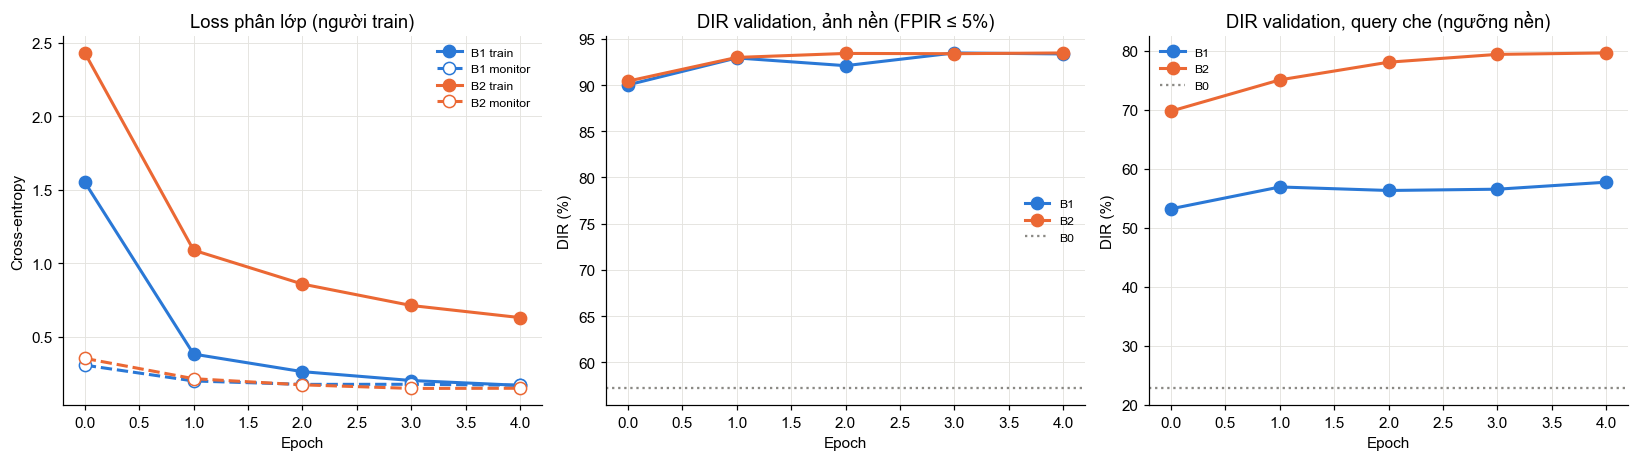

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for branch in ['B1', 'B2']:
    e = EPOCHS[EPOCHS.branch.eq(branch)]; v = VAL[VAL.run.eq(branch)]
    axes[0].plot(e.epoch, e.train_loss, 'o-', color=COLORS[branch], lw=2, ms=8, label=f'{branch} train')
    axes[0].plot(e.epoch, e.monitor_loss, 'o--', color=COLORS[branch], lw=2, ms=8, mfc='white', label=f'{branch} monitor')
    axes[1].plot(v.epoch, 100 * v.DIR, 'o-', color=COLORS[branch], lw=2, ms=8, label=branch)
    axes[2].plot(v.epoch, 100 * v.occluded_DIR, 'o-', color=COLORS[branch], lw=2, ms=8, label=branch)
axes[1].axhline(100 * B0_METRICS['DIR'], color=COLORS['B0'], lw=1.5, ls=':', label='B0')
axes[2].axhline(100 * B0_METRICS['occluded_DIR'], color=COLORS['B0'], lw=1.5, ls=':', label='B0')
axes[0].set(title='Loss phân lớp (người train)', xlabel='Epoch', ylabel='Cross-entropy')
axes[1].set(title='DIR validation, ảnh nền (FPIR ≤ 5%)', xlabel='Epoch', ylabel='DIR (%)')
axes[2].set(title='DIR validation, query che (ngưỡng nền)', xlabel='Epoch', ylabel='DIR (%)')
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); finish(fig, '01_training_and_validation_by_epoch')

## 6. Nạp lại model đã lưu và kiểm

Ô này không dùng model trong RAM. Nó nạp `*_best_encoder.pt` bằng `tai_model.load_encoder` (đúng cách bước 7 và demo sẽ dùng), đánh giá lại từ đầu và yêu cầu ra **đúng** số query nhận đúng, số người lạ bị nhận nhầm và ngưỡng đã ghi lúc train. `tai_model.embed` cũng phải cho embedding giống hệt đường đánh giá của notebook.

In [8]:
from tai_model import load_encoder, embed
FINAL = {'B0': (B0_METRICS, B0_BASE_Q, B0_OCC_Q)}
reload_rows = []
for branch in ['B1', 'B2']:
    model = load_encoder(branch, device=DEVICE, checkpoint=CKPT / f'{branch}_best_encoder.pt')
    info = model.checkpoint_info
    assert info['run_fingerprint'] == RUNS[branch]['fingerprint'] and info['epoch'] == RUNS[branch]['best']['epoch']
    metrics, base_q, occ_q = evaluate_model(model)
    recorded = RUNS[branch]['best']['metrics']
    for k in ['correct_accepted', 'unknown_accepted', 'occluded_correct_accepted']:
        assert metrics[k] == recorded[k], f'{branch}: {k} khác lúc train'
    assert abs(metrics['threshold'] - recorded['threshold']) < 1e-6
    a = embed(model, [PIX['val'][i] for i in range(16)])
    b = embed_pixels(model, np.arange(16))
    assert np.array_equal(a, b), 'tai_model.embed khác đường đánh giá'
    FINAL[branch] = (metrics, base_q, occ_q)
    path = CKPT / f'{branch}_best_encoder.pt'
    reload_rows.append({'nhánh': branch, 'epoch': info['epoch'], 'file': path.relative_to(ROOT).as_posix(),
                        'MB': round(path.stat().st_size / 2**20, 1), 'sha256': sha(path),
                        'khớp số liệu lúc train': True, 'embed() khớp': True})
    del model; gc.collect(); torch.cuda.empty_cache()
RELOAD = save(pd.DataFrame(reload_rows), '07_saved_model_reload_checks')
display(RELOAD)

,nhánh,epoch,file,MB,sha256,khớp số liệu lúc train,embed() khớp
0,B1,3,ban_giao_nhom/huan_luyen/checkpoints_full/B1_b...,89.9,c68f5a1e9aa926448f263efe5b03cb25582ffea4e2681f...,True,True
1,B2,4,ban_giao_nhom/huan_luyen/checkpoints_full/B2_b...,89.9,b57e1c7309cb580edfd6ed18702e884192daa7da064a99...,True,True


## 7. Kết quả trên validation

Mỗi model dùng ngưỡng riêng chọn trên ảnh nền. Khoảng tin cậy 95% lấy bằng bootstrap theo người (2.000 lần, người quen và người lạ lấy mẫu riêng), ghép cặp giữa các model nên hiệu số có CI riêng. CI tính tại checkpoint và ngưỡng đã chọn; chưa gồm biến thiên giữa các lượt train (mới có một seed).

In [9]:
rows, preds = [], []
for run, (m, base_q, occ_q) in FINAL.items():
    rows.append({'model': run, 'epoch': RUNS[run]['best']['epoch'] if run != 'B0' else None,
                 **{k: v for k, v in m.items() if k != 'eval_seconds'}})
    for condition, q in [('base', base_q), ('occluded', occ_q)]:
        f = q.copy(); f['run'] = run; f['condition'] = condition; f['threshold'] = np.float32(m['threshold'])
        f['accepted'] = f.top_score.to_numpy(np.float32) >= np.float32(m['threshold'])
        f['correct_accepted'] = f.accepted & f.top1_correct; f['unknown_accepted'] = f.accepted & ~f.is_known
        preds.append(f)
COMP = save(pd.DataFrame(rows), '08_model_comparison')
PRED = pd.concat(preds, ignore_index=True)
PRED = PRED.merge(VS[['image_id', 'kind']].rename(columns={'kind': 'occlusion_kind'}), on='image_id', how='left')
save(PRED, '08_predictions')
rt = pd.read_csv(TAB / '08_predictions.csv', float_precision='round_trip')
assert np.array_equal(rt.top_score.to_numpy(np.float32) >= rt.threshold.to_numpy(np.float32), PRED.accepted.to_numpy())

unknown_ids = sorted(Q[Q.role.eq('unknown_query')].canonical_identity.unique())
clusters = {}
for (run, condition), f in PRED.groupby(['run', 'condition']):
    k = f[f.is_known].groupby('canonical_identity').agg(h=('correct_accepted', 'sum'), n=('image_id', 'size')).reindex(known_ids).to_numpy(float)
    u = f[~f.is_known].groupby('canonical_identity').agg(h=('unknown_accepted', 'sum'), n=('image_id', 'size')).reindex(unknown_ids).to_numpy(float)
    clusters[(run, condition)] = (k, u)
rng = np.random.default_rng(SEED); boot = {key: [] for key in clusters}
for _ in range(CFG['bootstrap_repetitions']):
    ik = rng.integers(0, len(known_ids), len(known_ids)); iu = rng.integers(0, len(unknown_ids), len(unknown_ids))
    for key, (k, u) in clusters.items():
        boot[key].append([k[ik, 0].sum() / k[ik, 1].sum(), u[iu, 0].sum() / u[iu, 1].sum()])
boot = {key: np.array(v) for key, v in boot.items()}
ci = []
for key, arr in boot.items():
    for j, metric in enumerate(['DIR', 'FPIR']):
        lo, hi = np.quantile(arr[:, j], [.025, .975])
        ci.append({'so_sánh': key[0], 'điều kiện': key[1], 'chỉ số': metric, 'ci95_thấp': lo, 'ci95_cao': hi})
for a, b in [('B1', 'B0'), ('B2', 'B0'), ('B2', 'B1')]:
    for condition in ['base', 'occluded']:
        delta = boot[(a, condition)] - boot[(b, condition)]
        point = clusters[(a, condition)][0][:, 0].sum() / clusters[(a, condition)][0][:, 1].sum() \
            - clusters[(b, condition)][0][:, 0].sum() / clusters[(b, condition)][0][:, 1].sum()
        lo, hi = np.quantile(delta[:, 0], [.025, .975])
        ci.append({'so_sánh': f'{a}-{b}', 'điều kiện': condition, 'chỉ số': 'DIR', 'điểm': point, 'ci95_thấp': lo, 'ci95_cao': hi})
CI = save(pd.DataFrame(ci), '09_identity_bootstrap_CI')

show = COMP[['model', 'epoch', 'threshold', 'DIR', 'FPIR', 'rank1', 'occluded_DIR', 'occluded_FPIR']].copy()
for c in ['DIR', 'FPIR', 'rank1', 'occluded_DIR', 'occluded_FPIR']:
    show[c] = (100 * show[c]).round(2)
display(show.rename(columns={'DIR': 'DIR nền %', 'FPIR': 'FPIR nền %', 'rank1': 'Rank-1 %',
                             'occluded_DIR': 'DIR che %', 'occluded_FPIR': 'FPIR che %'}))
display(CI[CI.so_sánh.str.contains('-')].assign(**{c: lambda d, c=c: (100 * d[c]).round(2) for c in ['điểm', 'ci95_thấp', 'ci95_cao']}))

,model,epoch,threshold,DIR nền %,FPIR nền %,Rank-1 %,DIR che %,FPIR che %
0,B0,NaN,0.693074,57.16,5.00,82.86,22.73,2.75
1,B1,3.0,0.531435,93.49,4.85,97.00,56.51,4.32
2,B2,4.0,0.525244,93.49,4.95,97.08,79.62,4.70


,so_sánh,điều kiện,chỉ số,ci95_thấp,ci95_cao,điểm
12,B1-B0,base,DIR,32.59,40.35,36.32
13,B1-B0,occluded,DIR,30.86,36.70,33.78
14,B2-B0,base,DIR,32.40,40.49,36.32
15,B2-B0,occluded,DIR,54.16,59.49,56.89
16,B2-B1,base,DIR,-1.00,1.00,0.00
17,B2-B1,occluded,DIR,20.76,25.68,23.11


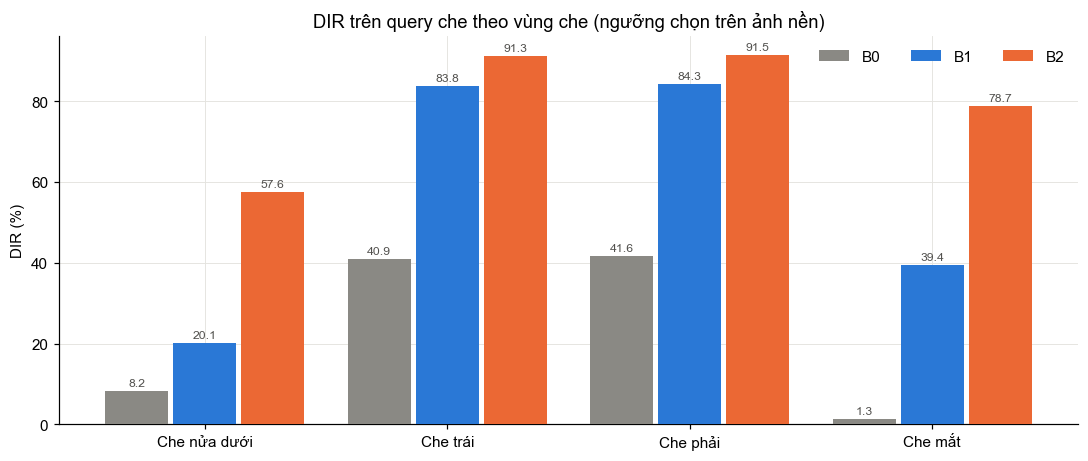

run,B0,B1,B2
occlusion_kind,,,
lower,8.22,20.06,57.63
left,40.89,83.81,91.27
right,41.58,84.29,91.53
eyes,1.28,39.40,78.70


In [10]:
KIND = (PRED[PRED.condition.eq('occluded')].groupby(['run', 'occlusion_kind'])
        .apply(lambda f: pd.Series({'known': int(f.is_known.sum()), 'DIR': f.correct_accepted.sum() / f.is_known.sum(),
                                    'FPIR': f.unknown_accepted.sum() / (~f.is_known).sum()}), include_groups=False)
        .reset_index())
save(KIND, '10_occluded_metrics_by_kind')
names = {'eyes': 'Che mắt', 'lower': 'Che nửa dưới', 'left': 'Che trái', 'right': 'Che phải'}
kinds = ['lower', 'left', 'right', 'eyes']
fig, ax = plt.subplots(figsize=(10, 4.3))
width = .26
for i, run in enumerate(['B0', 'B1', 'B2']):
    vals = [100 * KIND[(KIND.run == run) & (KIND.occlusion_kind == k)].DIR.iloc[0] for k in kinds]
    bars = ax.bar(np.arange(len(kinds)) + (i - 1) * (width + .02), vals, width, color=COLORS[run], label=run, zorder=3)
    ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2, color='#52514e')
base_vals = {r: 100 * FINAL[r][0]['DIR'] for r in FINAL}
ax.set_xticks(np.arange(len(kinds)), [names[k] for k in kinds])
ax.set(ylabel='DIR (%)', title='DIR trên query che theo vùng che (ngưỡng chọn trên ảnh nền)')
ax.legend(frameon=False, ncols=3); fig.tight_layout(); finish(fig, '02_occluded_DIR_by_kind')
display(KIND.pivot(index='occlusion_kind', columns='run', values='DIR').mul(100).round(2).loc[kinds])

## 8. Đối chiếu với lượt train song song

Bảng của lượt song song chép từ file Word `Validation_result_FaceNet.docx` (06/11/2026); lượt đó chưa gửi notebook, checkpoint hay kết quả trên query che. Hai lượt cùng cấu hình, cùng danh sách người train và cùng evaluator, nên chênh lệch chỉ nên đến từ thứ tự ngẫu nhiên, cách chọn epoch và cách cài đặt che. Cột B0 là phép kiểm hai bên chấm cùng một bộ query.

In [11]:
PARALLEL = pd.DataFrame([
    {'model': 'B0', 'DIR': .5716, 'FPIR': .0500, 'rank1': .8286, 'correct_accepted': 2115, 'unknown_accepted': 200, 'threshold': .69303},
    {'model': 'B1', 'DIR': .9478, 'FPIR': .0493, 'rank1': .9719, 'correct_accepted': 3507, 'unknown_accepted': 197, 'threshold': .54933},
    {'model': 'B2', 'DIR': .9454, 'FPIR': .0490, 'rank1': .9711, 'correct_accepted': 3498, 'unknown_accepted': 196, 'threshold': .57372}])
mine = COMP.set_index('model')
cross = []
for r in PARALLEL.itertuples():
    m = mine.loc[r.model]
    cross.append({'model': r.model, 'DIR lượt song song %': 100 * r.DIR, 'DIR notebook này %': round(100 * m.DIR, 2),
                  'chênh (điểm %)': round(100 * (m.DIR - r.DIR), 2),
                  'Rank-1 song song %': 100 * r.rank1, 'Rank-1 notebook này %': round(100 * m.rank1, 2),
                  'ngưỡng song song': r.threshold, 'ngưỡng notebook này': round(float(m.threshold), 5),
                  'DIR che notebook này %': round(100 * m.occluded_DIR, 2)})
CROSS = save(pd.DataFrame(cross), '11_cross_check_parallel_run')
assert abs(CROSS.loc[0, 'chênh (điểm %)']) < .01, 'B0 lệch: hai bên không chấm cùng một bộ query'
display(CROSS)

,model,DIR lượt song song %,DIR notebook này %,chênh (điểm %),Rank-1 song song %,Rank-1 notebook này %,ngưỡng song song,ngưỡng notebook này,DIR che notebook này %
0,B0,57.16,57.16,0.00,82.86,82.86,0.69303,0.69307,22.73
1,B1,94.78,93.49,-1.29,97.19,97.00,0.54933,0.53144,56.51
2,B2,94.54,93.49,-1.05,97.11,97.08,0.57372,0.52524,79.62


In [12]:
b1, b2 = COMP.set_index('model').loc['B1'], COMP.set_index('model').loc['B2']
d = CI[CI.so_sánh.eq('B2-B1')].set_index('điều kiện')
summary = {'checks': 'PASS', 'smoke_run': SMOKE, 'train_mode': TRAIN_MODE,
           'runs': {b: {'mode': r['mode'], 'best_epoch': r['best']['epoch'], 'fingerprint': r['fingerprint']} for b, r in RUNS.items()},
           'train_identities': len(labels), 'train_images': len(T), 'monitor_images': len(M), 'validation_images': len(V),
           'optimizer_steps_per_branch': int(EPOCHS[EPOCHS.branch.eq('B1')].optimizer_steps.sum()),
           'skipped_steps': EPOCHS.groupby('branch').skipped_steps.sum().to_dict(),
           'metrics': {r: {k: v for k, v in FINAL[r][0].items() if k != 'eval_seconds'} for r in FINAL},
           'B2_minus_B1_DIR': {c: {'point': d.loc[c, 'điểm'], 'ci95': [d.loc[c, 'ci95_thấp'], d.loc[c, 'ci95_cao']]} for c in d.index},
           'checkpoints': RELOAD.to_dict('records'), 'pixel_cache': PIXEL_MODE, 'raw_images_hashed_now': len(data),
           'test_used': False, 'external_used': False, 'environment': ENV, 'config': CFG,
           'train_and_validation_seconds': TRAIN_SECONDS, 'executed_at_utc': datetime.now(timezone.utc).isoformat(),
           'elapsed_seconds': time.perf_counter() - START}
jwrite(summary, 'execution_summary.json')
display(Markdown(f"""## 9. Kết luận

- **Train:** {vn(len(labels))} người, {vn(len(T))} ảnh/epoch, {CFG['epochs']} epoch, {vn(summary['optimizer_steps_per_branch'])} bước mỗi nhánh. Chế độ lượt này: B1 `{RUNS['B1']['mode']}`, B2 `{RUNS['B2']['mode']}`.
- **Ảnh nền (validation, FPIR ≤ 5%):** B0 {pct(B0_METRICS['DIR'])} → B1 {pct(b1.DIR)} (epoch {RUNS['B1']['best']['epoch']}), B2 {pct(b2.DIR)} (epoch {RUNS['B2']['best']['epoch']}). B2 − B1 = {pct(d.loc['base', 'điểm'], True)} điểm, CI 95% [{pct(d.loc['base', 'ci95_thấp'], True)}; {pct(d.loc['base', 'ci95_cao'], True)}].
- **Query che (giữ ngưỡng nền):** B0 {pct(B0_METRICS['occluded_DIR'])}, B1 {pct(b1.occluded_DIR)}, B2 {pct(b2.occluded_DIR)}. B2 − B1 = {pct(d.loc['occluded', 'điểm'], True)} điểm, CI 95% [{pct(d.loc['occluded', 'ci95_thấp'], True)}; {pct(d.loc['occluded', 'ci95_cao'], True)}].
- **Giới hạn:** validation là ảnh tổng hợp DigiFace, che là hình chữ nhật; một seed. Model tốt trên DigiFace chưa chắc tốt trên ảnh người thật, điều này chỉ trả lời được ở bước 7 (ROF/MFR2) và bước 8 (webcam).
- **Model đã lưu:** `{CKPT.name}/B1_best_encoder.pt`, `{CKPT.name}/B2_best_encoder.pt`, nạp lại cho đúng số liệu ở mục 6.
"""))

## 9. Kết luận

- **Train:** 1.600 người, 57.600 ảnh/epoch, 5 epoch, 36.000 bước mỗi nhánh. Chế độ lượt này: B1 `resumed_after_epoch_2`, B2 `trained_now`.
- **Ảnh nền (validation, FPIR ≤ 5%):** B0 57,16% → B1 93,49% (epoch 3), B2 93,49% (epoch 4). B2 − B1 = +0,00 điểm, CI 95% [−1,00; +1,00].
- **Query che (giữ ngưỡng nền):** B0 22,73%, B1 56,51%, B2 79,62%. B2 − B1 = +23,11 điểm, CI 95% [+20,76; +25,68].
- **Giới hạn:** validation là ảnh tổng hợp DigiFace, che là hình chữ nhật; một seed. Model tốt trên DigiFace chưa chắc tốt trên ảnh người thật, điều này chỉ trả lời được ở bước 7 (ROF/MFR2) và bước 8 (webcam).
- **Model đã lưu:** `checkpoints_full/B1_best_encoder.pt`, `checkpoints_full/B2_best_encoder.pt`, nạp lại cho đúng số liệu ở mục 6.


## 10. Dùng model đã lưu ở notebook khác hoặc demo

```python
import sys; sys.path.insert(0, 'ban_giao_nhom/huan_luyen')   # đường dẫn tính từ thư mục dự án
from tai_model import load_encoder, embed
model = load_encoder('B2')            # hoặc 'B1', 'B0'
vectors = embed(model, danh_sach_anh_mat)   # (N, 512), đã chuẩn hóa L2
```

Ảnh đưa vào `embed` là ảnh mặt đã cắt (PIL hoặc mảng RGB uint8). Với webcam, cắt mặt bằng MTCNN trước. Ngưỡng ở mục 7 chỉ đúng cho DigiFace validation; với webcam phải chọn lại bằng ảnh phiên 2.

Các file đầu ra: `full_outputs/tables/` (bảng), `full_outputs/figures/` (hình cho slide), `full_outputs/execution_summary.json` (tóm tắt lượt chạy). `full_outputs/cache/` và `*_last_resume.pt` là file tạm để chạy nhanh/train tiếp, không cần gửi cho nhóm.